# Collecte et validation des événements Aave V3 via Etherscan
### Contribution personnelle au projet « Quelle exposition les utilisateurs d'Aave construisent-ils ? »

*Louis Forgues — Projet de Python pour la data science, ENSAE, 2026*

Ce notebook présente ma partie du projet de groupe : la collecte des événements du protocole
Aave V3 par l'API d'Etherscan, leur validation par comparaison avec une seconde source, puis
le nettoyage et les premières statistiques descriptives.

Sommaire
1. Introduction
2. Collecte des événements via l'API Etherscan
3. Validation par une seconde source
4. Sélection des wallets et traçage des flux (BASTIEN)
5. Classification des tokens par famille économique (Ruben)
6. Nettoyage pour les statistiques
7. Statistiques descriptives
8. Bilan et limites

## 1. Introduction

### Problématique
Le projet de groupe cherche à répondre à la question suivante : quelle exposition les utilisateurs
d'Aave construisent-ils grâce au protocole de prêt-emprunt ? Autrement dit, une fois l'argent sorti
d'Aave, par un emprunt ou un retrait, que devient-il, et à quels actifs (dollar, ETH, bitcoin…) les
utilisateurs se retrouvent-ils exposés ?

### Contexte
Pour donner un peu de contexte, il est important de comprendre que les données que nous utilisons
sont publiques. Elles se trouvent en effet sur la blockchain Ethereum, un registre ouvert à tous qui
enregistre l'ensemble des opérations effectuées sur le réseau. Ces opérations, appelées transactions,
sont regroupées dans des blocs. Un nouveau bloc est ajouté environ toutes les 12 secondes, et les
blocs sont numérotés dans l'ordre croissant : chacun portant une date, le numéro de bloc permet de
retrouver l'ordre chronologique des opérations. Chaque transaction est identifiée par un hash unique
et peut faire appel à des programmes, les smart contracts, qui émettent alors des événements (ou logs)
décrivant ce qui s'est passé, par exemple qu'un utilisateur a emprunté une certaine quantité d'USDC.

Le projet se concentre plus particulièrement sur les protocoles de prêt-emprunt, et parmi eux sur
Aave. Le protocole de prêt d'Aave est un ensemble de smart contracts qui joue le rôle d'une banque
automatique. Les utilisateurs y déposent des cryptomonnaies pour toucher des intérêts (supply), en
empruntent d'autres en échange d'une garantie (borrow), remboursent (repay) ou retirent leurs fonds
(withdraw). Si leur garantie ne suffit plus, leur position est liquidée (liquidation). Les
cryptomonnaies prêtées et empruntées sont par exemple USDC, USDT et DAI, des stablecoins qui valent
un dollar, WETH, qui représente de l'ether, ou WBTC, qui représente du bitcoin. Chacune de ces
actions émet un événement du contrat principal d'Aave V3, appelé Pool, et ce sont ces événements
que nous cherchons à récupérer.

### Une stratégie à deux sources
Avant de pouvoir utiliser les données, notre première étape était de les récupérer. Afin de limiter
les erreurs, nous avons élaboré une stratégie consistant à récupérer les mêmes événements par deux
sources différentes, de manière indépendante. J'ai travaillé sur la première, l'API d'Etherscan,
tandis qu'un autre membre du groupe interrogeait directement un nœud Ethereum avec la bibliothèque
web3. Si les deux méthodes renvoient exactement les mêmes événements, nous pouvons avoir confiance
dans nos données ; si elles diffèrent, la comparaison permet de repérer les événements manquants
ou mal décodés.

Etherscan est un explorateur de la blockchain Ethereum : il lit et range toutes les transactions,
tous les blocs et tous les événements émis par les contrats, et les met gratuitement à disposition
sur un site web et via une API, qui nous permet de les récupérer directement dans Python
([documentation](https://docs.etherscan.io/)).

### Travaux existants et apport du projet
Plusieurs travaux récents étudient le prêt décentralisé à partir des mêmes données publiques que nous,
c'est-à-dire les transactions enregistrées sur la blockchain Ethereum.

Le plus proche de notre sujet est une étude de la Banque du Canada consacrée à Aave V3, le même marché
que celui que nous étudions : Jonathan Chiu, *DeFi Lending: Returns, Leverage, and Liquidation Risk*,
Staff Analytical Paper 2026-13
([lien vers l'étude](https://www.bankofcanada.ca/2026/analytical-paper/staff-analytical-paper-2026-13)).
À partir de données transaction par transaction, l'auteur s'intéresse surtout au fonctionnement du
protocole lui-même : la façon dont Aave génère ses revenus, le comportement des emprunteurs et le risque
de liquidation. Il montre notamment que les revenus du protocole sont concentrés sur quelques tokens, que
de nombreux utilisateurs pratiquent un levier récursif malgré l'obligation de déposer plus qu'ils
n'empruntent, et que les liquidations surviennent par vagues.

Deux documents de travail de la Banque des règlements internationaux (BRI) complètent ce tableau.
Heimbach et Huang (2024), *DeFi Leverage* ([lien](https://www.bis.org/publ/work1171.htm)), reconstruisent
portefeuille par portefeuille les dépôts et les dettes des emprunteurs pour mesurer leur levier, qui se
situe en général entre 1,4 et 1,9. Cornelli, Gambacorta, Garratt et Reghezza (2025), *Why DeFi lending?
Evidence from Aave V2* ([lien](https://www.bis.org/publ/work1183.htm)), étudient les motivations des
utilisateurs et concluent que les dépôts sont surtout motivés par la recherche de rendement, et les
emprunts principalement par la spéculation.

Ces travaux utilisent donc les mêmes données que nous, mais pas avec la même approche : ils regardent ce
qui se passe à l'intérieur du protocole, c'est-à-dire ce que les utilisateurs déposent, empruntent et
remboursent sur Aave. Notre projet s'intéresse à l'exposition que les utilisateurs construisent grâce à
Aave, ce qui oblige à suivre l'argent après sa sortie du protocole. La vraie nouveauté de notre travail se
situe dans cette étape de filtrage et de traçage, réalisée par un autre membre du groupe et présentée en partie 4
(voir aussi le fichier `README_FILTERING.md`) :
- nous ne gardons que les wallets, c'est-à-dire les adresses contrôlées par une personne, et retirons les
  smart contracts (routeurs, coffres, robots), dont les historiques ne traduisent pas une décision ;
- nous ne gardons que les utilisateurs dont l'historique est complet, car un historique coupé fausserait
  le suivi dès le premier transfert manquant ;
- pour chaque utilisateur, nous tenons un registre de l'argent issu d'Aave, token par token. Chaque
  transaction reçoit une fraction tracée comprise entre 0 et 1, la part payée avec de l'argent issu
  d'Aave. Une transaction Aave a une fraction de 1 ; pour les autres, la fraction dépend de la quantité
  d'argent tracé encore disponible pour les tokens envoyés. L'argent qui arrive de l'extérieur n'est jamais
  compté, et un solde ne peut pas descendre sous zéro.

Sur les 51,4 millions de transferts des utilisateurs conservés, 9,25 millions (18 %) peuvent ainsi être
rattachés à de l'argent issu d'Aave. C'est ce suivi qui permet de voir, par exemple, qu'un utilisateur
emprunte des dollars puis les échange contre de l'ETH, ce qui n'est pas visible en regardant le protocole
seul.

### Bibliothèques utilisées
On importe ici l'ensemble des bibliothèques utilisées dans mes codes de collecte, de comparaison
et de statistiques descriptives.

In [ ]:
import glob                                  # pour retrouver des fichiers à partir d'un motif
import os                                    # pour lire les variables d'environnement (la clé d'API, le nom du bucket SSP Cloud)
import time                                  # pour faire des pauses entre les appels à l'API (limite de 3 requêtes par seconde)
from datetime import datetime, timezone      # pour convertir les dates

import matplotlib.pyplot as plt              # pour les graphiques
import numpy as np                           # pour les calculs numériques
import pandas as pd                          # pour manipuler des tableaux de données (DataFrame)
import requests                              # pour envoyer les requêtes à l'API d'Etherscan et recevoir les réponses
import s3fs                                  # pour lire les fichiers stockés sur le SSP Cloud
from dotenv import load_dotenv               # pour lire la clé d'API dans le fichier .env

## 2. Collecte des événements via l'API Etherscan

### 2.1 Les données utilisées dans ce notebook
La collecte complète demande une clé d'API personnelle et plusieurs heures d'appels à Etherscan.
Elle a donc été réalisée une seule fois avec mon script `fetch_events_etherscan.py`, qui produit un
fichier CSV par type d'événement. Ces fichiers sont stockés dans mon dossier `diffusion` du SSP Cloud,
qui peut être lu par tout utilisateur du SSP Cloud.

Ce notebook peut ainsi s'exécuter sans clé d'API : par défaut (`UTILISER_API = False`), il lit les
fichiers déjà collectés. Avec `UTILISER_API = True` et une clé Etherscan dans un fichier `.env`, il
relance la collecte complète.

In [ ]:
UTILISER_API = False   # True : relance la collecte (il faut une clé Etherscan dans .env)

EVENEMENTS = ["supply", "withdraw", "borrow", "repay", "liquidation"]
TEXTE = {"amount_raw": str, "debt_to_cover_raw": str}   # montants trop grands pour un entier classique

if UTILISER_API:
    %run "fetch_events_test_data.py/fetch_events_etherscan.py"      # mon script de collecte, lancé tel quel
    dfs = {e: pd.read_csv(f"aave_{e}.csv", dtype=TEXTE) for e in EVENEMENTS}
else:
    fs = s3fs.S3FileSystem()   # se connecte au stockage du SSP Cloud avec le compte de l'utilisateur
    dfs = {}
    for e in EVENEMENTS:
        with fs.open(f"louis75/diffusion/etherscan/aave_{e}.csv") as f:
            dfs[e] = pd.read_csv(f, dtype=TEXTE)

for e, df in dfs.items():
    print(e, df.shape)

Les cellules suivantes reprennent mon script de collecte, sans modification. Celles qui appellent
l'API commencent par la commande `%%api`, définie ci-dessous : elles ne sont exécutées que si
`UTILISER_API = True`, ce qui permet de lancer tout le notebook sans clé.

In [ ]:
from IPython.core.magic import register_cell_magic


@register_cell_magic
def api(line, cell):
    # exécute la cellule seulement si UTILISER_API = True
    if UTILISER_API:
        get_ipython().run_cell(cell)
    else:
        print("Cellule non exécutée : elle appelle l'API Etherscan (UTILISER_API = False).")

### 2.2 L'interrogation de l'API
Pour interroger l'API d'Etherscan, il faut d'abord disposer d'une clé d'API, que l'on obtient
gratuitement en créant un compte sur le site. Cette clé identifie l'utilisateur à chaque requête et
permet à Etherscan de limiter le nombre d'appels : la version gratuite autorise 3 requêtes par seconde
et 100 000 par jour. Comme il s'agit d'un identifiant personnel, la clé n'est jamais écrite dans le
code. Elle est rangée dans un fichier `.env`, exclu du dépôt GitHub, et lue au moment de l'exécution
grâce à la bibliothèque `dotenv`.

In [ ]:
%%api
#l'objectif ici est de récupérer la clé API qui est sécurisée dans un dossier env 
if "ETHERSCAN_API_KEY" not in globals():
    from dotenv import load_dotenv
    load_dotenv()
    ETHERSCAN_API_KEY = os.getenv("ETHERSCAN_API_KEY")

assert ETHERSCAN_API_KEY not in (None, "your-actual-etherscan-api-key"), "Set your Etherscan key (.env)" #on vérifie qu'on a bien la clé 
print("Key loaded.")

Grâce à cette clé, on peut récupérer de nombreuses informations sur la blockchain : le dernier bloc
produit, les transactions d'une adresse, les transferts de tokens ou encore les événements émis par
un contrat. Toutes les requêtes passent par la même adresse, et c'est le choix des paramètres qui
détermine l'information renvoyée. Il a donc fallu se familiariser avec la documentation de l'API
pour être en mesure de renseigner correctement ces paramètres :
- `chainid` indique la blockchain interrogée. Etherscan gère en effet plusieurs blockchains avec la
  même adresse, et la valeur 1 correspond à Ethereum ;
- `module` indique la famille de requêtes. Le module `proxy` transmet la question directement à un
  nœud Ethereum, le module `logs` donne accès aux événements ;
- `action` précise la requête au sein du module, par exemple `eth_blockNumber` pour obtenir le
  numéro du dernier bloc ;
- `apikey` contient la clé d'API.

Pour vérifier que l'environnement fonctionne, on commence par une requête simple : demander le
numéro du dernier bloc produit.

In [ ]:
ETHERSCAN_BASE_URL = "https://api.etherscan.io/v2/api"
ETH_CHAIN_ID = 1 #car etherscan gère plusieurs blockchain avec la même URL

In [ ]:
%%api
# on teste si l'environnement fonctionne bien en récupérant le dernier bloc
params = {
    "chainid": ETH_CHAIN_ID,
    "module": "proxy",
    "action": "eth_blockNumber",
    "apikey": ETHERSCAN_API_KEY,
}
r = requests.get(ETHERSCAN_BASE_URL, params=params) #on envoie la requête
etherscan_block = int(r.json()["result"], 16) #ici on traduit juste le résultat car il est en r.json
print(r.json())
print("Etherscan says latest block is:", etherscan_block)

La réponse est renvoyée au format JSON, et les nombres y sont écrits en hexadécimal, c'est-à-dire
en base 16, précédés de `0x`. Il faut donc les convertir en nombres décimaux. Par exemple, la valeur
`0x180CEED` correspond au bloc 25 218 797, qui a servi de bloc de fin pour notre collecte. Etherscan
renvoyant simplement `0x` pour la valeur 0, on écrit une petite fonction de conversion qui gère ce cas.

In [ ]:
#commande pour décoder
print(int("0x180CEED", 16))

def decode(valeur):
    # Etherscan renvoie "0x" pour la valeur 0
    return int(valeur, 16) if valeur not in ("0x", "") else 0

### 2.3 Repérer les événements Aave
Une fois l'API maîtrisée, il faut lui indiquer précisément quels événements récupérer. Un événement
est identifié par deux informations. La première est l'adresse du contrat qui l'émet, ici le Pool
d'Aave V3, le contrat principal du protocole. La seconde est son `topic0`, une empreinte (un hash)
calculée à partir du nom de l'événement et du type de ses paramètres, par exemple
`Borrow(address,address,address,uint256,uint8,uint256,uint16)` pour un emprunt. Chaque type
d'événement possède donc son propre `topic0`, et nous en avons besoin de cinq : un pour chacune des
actions décrites en introduction.

On limite enfin la recherche à un intervalle de blocs : du bloc 16 291 127, qui correspond au
lancement d'Aave V3 sur Ethereum, au bloc 25 218 797, dernier bloc au moment de la collecte.

In [ ]:
#on va définir ce dont on a besoin pour récupérer les actions d'emprunts et de prêts
AAVE_V3_POOL = "0x87870Bca3F3fD6335C3F4ce8392D69350B4fA4E2"

START_BLOCK = 16291127 #bloc du début de notre étude 
END_BLOCK = 25218797    #bloc de fin 

#récupération des events borrow, supply, repay, liquidations, withdraw

EVENTS= {
    "supply": "0x2b627736bca15cd5381dcf80b0bf11fd197d01a037c52b927a881a10fb73ba61",
    "withdraw": "0x3115d1449a7b732c986cba18244e897a450f61e1bb8d589cd2e69e6c8924f9f7",
    "borrow": "0xb3d084820fb1a9decffb176436bd02558d15fac9b0ddfed8c465bc7359d7dce0",
    "repay": "0xa534c8dbe71f871f9f3530e97a74601fea17b426cae02e1c5aee42c96c784051",
    "liquidation": "0xe413a321e8681d831f4dbccbca790d2952b56f977908e45be37335533e005286"
}

Pour chaque type d'événement, on interroge alors le module `logs` avec l'action `getLogs`, en lui donnant l'adresse du Pool, le `topic0` de l'événement et l'intervalle de blocs. Nous avons d'abord testé cette requête sur les seuls emprunts (Borrow), sur toute la période étudiée. Elle a bien renvoyé une liste d'événements, mais nous avons rapidement rencontré un problème : le nombre de résultats obtenus était anormalement faible. Nous avons donc dû segmenter nos requêtes, comme l'explique la partie suivante.

### 2.4 Contourner la limite de 1 000 résultats par appel
En exécutant le code précédent, nous avons obtenu des tableaux plafonnés à 1 000 lignes, et ce pour
chaque type d'événement. Ce résultat nous a paru étrange : sur près de 9 millions de blocs, soit plus
de trois ans d'activité, il était peu vraisemblable qu'il n'y ait que 1 000 emprunts, exactement autant
que de dépôts ou de remboursements. Nous nous sommes alors rendu compte que le problème venait des
appels à l'API : chaque requête `getLogs` renvoie au plus 1 000 résultats, et tous les événements
suivants sont simplement ignorés.

J'ai d'abord pensé à segmenter l'intervalle de blocs en tranches fixes de 100 000 blocs, et à envoyer
une requête par tranche. Cette méthode s'est cependant révélée peu optimale. L'activité d'Aave est en
effet très irrégulière : certaines tranches, pendant les périodes les plus actives, dépassaient encore
les 1 000 événements et restaient donc incomplètes, tandis que beaucoup d'autres, pour les événements
plus rares comme les liquidations, donnaient lieu à des requêtes presque vides. Il aurait fallu choisir
une taille de tranche différente selon la période et le type d'événement.

La solution qui a finalement fonctionné consiste à adapter le découpage à l'activité, en coupant
l'intervalle en deux à chaque fois que la limite est atteinte. Si une requête renvoie moins de 1 000
événements, l'intervalle est complet et on garde le résultat. Si elle en renvoie 1 000, il en manque
probablement, et on relance la même requête sur chacune des deux moitiés de l'intervalle, qui seront
à leur tour coupées si nécessaire. Par exemple, si l'intervalle allant du bloc 0 au bloc 250 renvoie
1 000 emprunts, on interroge séparément les blocs 0 à 125 et 126 à 250. Le découpage est ainsi fin
dans les périodes très actives et large ailleurs, ce qui limite le nombre d'appels.

Une fonction qui s'appelle elle-même de cette façon est dite récursive. Avant d'écrire la fonction
de découpage, on renforce l'appel à l'API : la fonction `etherscan_get` relance automatiquement une
requête qui échoue, par exemple à cause d'une coupure réseau ou d'un dépassement du nombre d'appels
autorisés, en attendant un peu plus longtemps à chaque tentative. Après chaque requête réussie, elle
marque une pause de 0,35 seconde pour respecter la limite de 3 requêtes par seconde.

In [ ]:
#on divise par deux à chaque fois que ça sature

PAGE = 1000

def etherscan_get(params, retries=5):
    for attempt in range(retries):
        try:
            result = requests.get(ETHERSCAN_BASE_URL, params=params, timeout=15).json().get("result")
        except requests.exceptions.RequestException as err:   # timeout
            result = f"erreur réseau : {err}"
        if isinstance(result, list):  #on teste si c'est une liste
            time.sleep(0.35)
            return result
        print(f"  tentative {attempt + 1}/{retries} échouée : {result}", flush=True)
        time.sleep(1 + attempt)
    raise RuntimeError(f"Erreur Etherscan : {result}")

La fonction `fetch_logs` applique ensuite le découpage. Le milieu de l'intervalle est calculé par
une division entière (`//`), et les résultats des deux moitiés sont mis bout à bout avec `+`.

In [ ]:
def fetch_logs(topic0, start, end):
    params = {
        "chainid": ETH_CHAIN_ID, "module": "logs", "action": "getLogs",
        "address": AAVE_V3_POOL, "topic0": topic0,
        "fromBlock": start, "toBlock": end,
        "page": 1, "offset": PAGE,
        "apikey": ETHERSCAN_API_KEY,
    }
    logs = etherscan_get(params)
    if len(logs) < PAGE:
        return logs
    mid = (start + end) // 2
    return fetch_logs(topic0, start, mid) + fetch_logs(topic0, mid + 1, end)

### 2.5 Décodage des données brutes
Les événements ainsi récupérés sont des données brutes, très difficiles à lire. Pour s'en rendre
compte, on peut afficher les cinq premiers emprunts tels qu'Etherscan les renvoie.

In [ ]:
%%api
logs_bruts = fetch_logs(EVENTS["borrow"], 16496817, 16500000)   # premiers blocs d'activité d'Aave V3
for log in logs_bruts[:5]:
    print(log, "\n")

Chaque événement se présente sous la forme d'un dictionnaire. Les champs communs (`blockNumber`,
`timeStamp`, `transactionHash`, `logIndex`) sont faciles à repérer, mais les informations propres à
l'événement, comme l'utilisateur, l'actif ou le montant, sont réparties entre deux champs sans aucune
légende. Le champ `topics` est une liste dont chaque élément contient un paramètre dit indexé. Le champ
`data` est un long texte dans lequel les autres paramètres sont écrits les uns à la suite des autres,
sans distinction entre les caractères qui correspondent à chaque caractéristique de l'événement.

Pour décoder ces données, il a donc fallu consulter la documentation d'Aave pour chaque événement afin
de savoir où se trouve chaque information. On sait ainsi que chaque paramètre occupe exactement 64
caractères, et que l'ordre des paramètres dépend de l'événement. Par exemple, pour un emprunt (Borrow),
le premier bloc de 64 caractères de `data` correspond à l'utilisateur et le deuxième au montant
emprunté, tandis que l'actif emprunté se trouve dans le deuxième élément de `topics`. Le tableau
suivant résume la position des informations récupérées pour chaque événement.

| Événement | Actif | Utilisateur | Montant | Autre |
|---|---|---|---|---|
| supply, borrow | `topics[1]` | 1ᵉʳ bloc de `data` | 2ᵉ bloc de `data` | |
| withdraw, repay | `topics[1]` | `topics[2]` | 1ᵉʳ bloc de `data` | |
| liquidation | | `topics[3]` | 1ᵉʳ bloc de `data` (dette remboursée) | liquidateur : 3ᵉ bloc de `data` |

Une adresse Ethereum ne fait que 40 caractères : elle est complétée par des zéros à gauche pour
occuper un bloc de 64. La fonction `addr` ne garde donc que les 40 derniers caractères. La fonction
`decode_log` découpe ensuite `data` en blocs de 64 caractères, puis va chercher chaque information à
la bonne place selon le type d'événement.

In [ ]:
def addr(x):
    return "0x" + x[-40:]       # une adresse = les 40 derniers caractères

def decode_log(event, log):
    data = log["data"][2:]                                   # on enlève le "0x"
    w = [data[i:i+64] for i in range(0, len(data), 64)]      # data découpé en mots de 32 octets
    t = log["topics"]

    row = {                                                  # on stocke dans une variable...
        "event": event,
        "block_number": decode(log["blockNumber"]),
        "timestamp": decode(log["timeStamp"]),
        "tx_hash": log["transactionHash"],
        "log_index": decode(log["logIndex"]),
    }

    if event in ("supply", "borrow"):                        
        row["reserve"] = addr(t[1])
        row["user"] = addr(w[0])
        row["amount_raw"] = int(w[1], 16)

    elif event in ("withdraw", "repay"):
        row["reserve"] = addr(t[1])
        row["user"] = addr(t[2])
        row["amount_raw"] = int(w[0], 16)

    elif event == "liquidation":
        row["user"] = addr(t[3])
        row["debt_to_cover_raw"] = int(w[0], 16)
        row["liquidator"] = addr(w[2])

    return row                                               # on return à la fin 

Il ne reste plus qu'à appliquer le découpage et le décodage aux cinq types d'événements sur toute la
période, et à enregistrer un fichier CSV par événement. Ce sont ces fichiers qui ont été déposés sur le
SSP Cloud et chargés au début de ce notebook.

In [ ]:
%%api
tables = {}
for event, topic0 in EVENTS.items():
    logs = fetch_logs(topic0, START_BLOCK, END_BLOCK)
    print(f"{event}: {len(logs)} logs")
    tables[event] = pd.DataFrame([decode_log(event, log) for log in logs])
    tables[event].to_csv(f"aave_{event}.csv", index=False)
print(tables)

### 2.6 Les données obtenues
Voici un aperçu de chacun des cinq fichiers une fois décodés, triés par ordre chronologique (numéro
de bloc, puis position dans la transaction).

In [ ]:
for e, df in dfs.items():
    print(f"{e} : {len(df):,} événements")
    display(df.sort_values(["block_number", "log_index"]).head())

Les données sont désormais lisibles : chaque ligne est une action d'un utilisateur sur Aave, avec sa
date, l'actif concerné et le montant. Avant de les analyser, il reste cependant à vérifier qu'elles sont
complètes et correctement décodées. Une erreur dans la position d'un paramètre ou un appel à l'API
silencieusement incomplet suffirait en effet à fausser toute la suite. C'est tout l'intérêt de la
stratégie à deux sources présentée en introduction : la partie suivante compare ces événements à ceux
récupérés indépendamment auprès d'un nœud Ethereum.

## 3. Validation par une seconde source

### 3.1 Les deux sources
Comme expliqué en introduction, les mêmes événements ont été récupérés une seconde fois, de manière
indépendante, par un autre membre du groupe. Il a interrogé directement un nœud Ethereum grâce à la
bibliothèque `web3`, sans passer par Etherscan (script `fetch_events_web3.py`, qui utilisait
initialement le fournisseur Alchemy, d'où le nom `alc` donné à ces données). Si nos deux méthodes sont
correctes, elles doivent renvoyer exactement les mêmes événements, avec les mêmes valeurs.

On rassemble d'abord les cinq tableaux Etherscan en un seul, la référence (`ref`), puis on charge le
fichier de la seconde source, stocké au format Parquet sur le SSP Cloud. Les montants sont lus comme du
texte, car ils sont trop grands pour être stockés dans un entier classique.

In [ ]:
# Charger les deux sources ------------------------------------------------
ref = pd.concat(dfs.values(), ignore_index=True)                       # les 5 CSV Etherscan
alc = pd.read_parquet("s3://louis75/diffusion/aave_v3_events.parquet")  # la seconde source

alc["amount_raw"] = alc["amount_raw"].astype(str)

print("référence :", ref.shape, "| alchemy :", alc.shape)
print("colonnes alchemy :", list(alc.columns))

### 3.2 Mettre les deux sources au même format
Pour comparer deux tableaux ligne à ligne, il faut que les mêmes informations y soient écrites de la
même façon. Or le nœud renvoie les adresses avec des majuscules, alors qu'Etherscan les écrit en
minuscules : une même adresse serait alors considérée comme différente. On passe donc toutes les
adresses et tous les hash en minuscules, et on s'assure que les numéros de bloc et les positions dans
la transaction sont bien des nombres entiers dans les deux tableaux.

In [ ]:
# Mettre les deux au même format ---------------------------------------------
# Alchemy écrit les adresses avec des majuscules, les CSV en minuscules -> tout en minuscules
for df in (ref, alc):
    for col in ["event", "tx_hash", "reserve", "user"]:
        if col in df:
            df[col] = df[col].str.lower()
    df["block_number"] = df["block_number"].astype("int64")
    df["log_index"] = df["log_index"].astype("int64")

### 3.3 Garder la période commune et retirer les doublons
Les deux collectes n'ont pas été faites au même moment et ne couvrent donc pas exactement la même
période. Un événement présent dans une seule source pourrait simplement être en dehors de la période de
l'autre. On ne garde donc que les blocs couverts par les deux sources.

On vérifie ensuite qu'il n'y a pas de doublons. Un événement est identifié de façon unique par le hash
de sa transaction et sa position dans cette transaction (`tx_hash`, `log_index`) : deux lignes qui
partagent ces deux valeurs décrivent le même événement.

In [ ]:
# Garder seulement la période commune ----------------------------------------
debut = max(ref["block_number"].min(), alc["block_number"].min())
fin = min(ref["block_number"].max(), alc["block_number"].max())
print("Période commune : blocs", debut, "->", fin)

ref = ref[ref["block_number"].between(debut, fin)]
alc = alc[alc["block_number"].between(debut, fin)]

KEY = ["tx_hash", "log_index"]     # identifie un log de façon unique
print("Doublons : référence =", ref.duplicated(KEY).sum(), "| alchemy =", alc.duplicated(KEY).sum())
ref = ref.drop_duplicates(KEY)
alc = alc.drop_duplicates(KEY)

### 3.4 Quels événements sont présents dans les deux sources ?
On fusionne les deux tableaux sur l'identifiant (`tx_hash`, `log_index`) en gardant toutes les lignes
des deux côtés (`how="outer"`). L'option `indicator=True` ajoute une colonne `_merge` qui indique, pour
chaque événement, s'il est présent dans les deux sources (`both`), seulement chez Etherscan
(`left_only`) ou seulement dans la seconde source (`right_only`). Si les deux collectes sont complètes,
tous les événements doivent être dans la catégorie `both`.

In [ ]:
#  Quels logs sont dans les deux sources ? --------------------------------------
cols = [c for c in ["event", "block_number", "reserve", "user", "amount_raw"] if c in ref and c in alc]

merged = ref[KEY + cols].merge(alc[KEY + cols], on=KEY, how="outer",
                               suffixes=("_ref", "_alc"), indicator=True)

# both = dans les deux | left_only = seulement dans la référence | right_only = seulement chez Alchemy
print(merged["_merge"].value_counts())

if "event" in cols:
    merged["event"] = merged["event_ref"].fillna(merged["event_alc"])
    print(pd.crosstab(merged["event"], merged["_merge"]))

### 3.5 Les valeurs sont-elles identiques ?
Pour les événements présents dans les deux sources, on vérifie enfin, colonne par colonne, que les
valeurs sont les mêmes : numéro de bloc, actif, utilisateur et montant. Pour chaque colonne, on compte
les différences et on affiche quelques exemples.

In [ ]:
# Pour les logs présents partout : les valeurs sont-elles identiques ? -------
both = merged[merged["_merge"] == "both"]

for col in cols:
    diff = both[col + "_ref"] != both[col + "_alc"]
    print(f"{col} : {diff.sum()} différence(s) sur {len(both)}")
    if diff.any():
        print(both.loc[diff, KEY + [col + "_ref", col + "_alc"]].head(5).to_string(index=False))

Les numéros de bloc et les actifs sont identiques pour tous les événements communs. En revanche, la
colonne `user` présente de nombreuses différences. Pour s'assurer qu'elles ne viennent pas d'une simple
différence d'écriture, on refait la comparaison après avoir passé les deux colonnes en minuscules.

In [ ]:
both["user_ref_clean"] = both["user_ref"].str.lower()
both["user_alc_clean"] = both["user_alc"].str.lower()

diff_user = both[
    both["user_ref_clean"] != both["user_alc_clean"]
]

print("Différences réelles :", len(diff_user))

print(
    diff_user[
        KEY + ["user_ref", "user_alc"]
    ].head(20).to_string(index=False)
)

### 3.6 D'où viennent les différences sur l'utilisateur ?
La comparaison fait apparaître 518 065 différences sur l'utilisateur, soit environ 13 % des 3 919 908
événements communs. Elles ne correspondent pas à une erreur de collecte, mais à une différence de
définition. Pour un dépôt (Supply) ou un emprunt (Borrow), l'événement Aave contient en effet deux
adresses. La première, `user`, est celle qui envoie la transaction, autrement dit l'appelant. La
seconde, `onBehalfOf`, est celle du compte dont la position change sur Aave, c'est-à-dire celui qui
reçoit le dépôt ou qui porte la dette. Ces deux adresses sont le plus souvent identiques, mais pas
toujours : un utilisateur peut déposer pour le compte d'un autre, et beaucoup passent par un smart
contract intermédiaire (une application ou un agrégateur) qui appelle Aave à leur place.

Or les deux sources n'ont pas retenu la même adresse. Ma fonction `decode_log` récupère l'appelant,
situé dans le premier bloc de `data`, tandis que la seconde source range dans `user` le compte
`onBehalfOf`, situé dans `topics[2]`, et conserve l'appelant dans une colonne à part, `caller`.
Pour le vérifier, on regarde d'abord à quels événements correspondent les différences, puis on compare
mon `user` à la colonne `caller` de la seconde source. Si l'explication est la bonne, les différences
ne doivent concerner que les dépôts et les emprunts, et l'écart avec `caller` doit être nul.

In [ ]:
# Vérification : mon "user" correspond-il au "caller" de la seconde source ?
verif = ref[KEY + ["event", "user"]].merge(alc[KEY + ["user", "caller"]], on=KEY,
                                           suffixes=("_ref", "_alc"))
verif["caller"] = verif["caller"].str.lower()

# 1. à quels événements correspondent les différences sur user ?
ecart_user = verif["user_ref"] != verif["user_alc"]
print("Différences sur user, par type d'événement :")
print(verif.loc[ecart_user, "event"].value_counts(), "\n")

# 2. pour les dépôts et les emprunts, mon user est-il bien l'appelant (caller) ?
sb = verif[verif["event"].isin(["supply", "borrow"])]
ecart_caller = sb["user_ref"] != sb["caller"]
print(f"supply et borrow : {ecart_caller.sum()} différence(s) entre mon user et son caller, sur {len(sb):,} événements")
print(f"Part des dépôts et emprunts faits pour le compte d'un autre : "
      f"{100 * (sb['user_alc'] != sb['caller']).mean():.1f} %")

### 3.7 Conclusion de la validation
La comparaison des deux sources est très satisfaisante. Les 3 919 908 événements sont retrouvés dans
les deux collectes, et pour chacun d'eux le numéro de bloc et l'actif concerné sont identiques. Les
différences sur l'utilisateur ne traduisent pas une erreur : elles viennent du fait que, pour les dépôts
et les emprunts, chaque source a retenu une adresse différente, l'appelant de mon côté et le compte
bénéficiaire de l'autre. Les deux méthodes de collecte, pourtant indépendantes, donnent donc les mêmes
données, ce qui nous permet d'avoir confiance dans leur exhaustivité comme dans leur décodage.

Cette comparaison a également permis de faire un choix pour la suite du projet. Pour étudier
l'exposition des utilisateurs, c'est le compte bénéficiaire (`onBehalfOf`) qui compte, puisque c'est
lui qui détient le dépôt ou qui porte la dette. Le groupe a donc retenu pour la suite les données de la
seconde source, qui renseignent les deux adresses, ma collecte servant de contrôle.

## 4. Sélection des wallets et traçage des flux (BASTIEN)

Cette étape a été réalisée par Bastien. Elle part des événements validés en partie 3 et de l'historique
complet des transferts de chaque utilisateur, et produit le fichier des transferts rattachés à de l'argent
issu d'Aave, utilisé pour les statistiques de la partie 7. Elle comporte deux grandes étapes, décrites en
introduction :
- la sélection des utilisateurs : on ne garde que les wallets dont l'historique est complet ;
- le traçage des flux : pour chaque utilisateur, un registre suit, token par token, l'argent issu d'Aave,
  et chaque transaction reçoit une fraction tracée comprise entre 0 et 1.

Le détail du code et des choix est présenté dans le notebook de Bastien :
[notebook de Bastien (Google Colab)](https://colab.research.google.com/drive/15Xjtg4EsCXvRAc0zZ5Ne-Ykn_M4ezn6t?usp=sharing).

## 5. Classification des tokens par famille économique (Ruben)

Cette étape a été réalisée par Ruben. Les transferts tracés font intervenir plus de 13 000 tokens
différents. Pour parler d'exposition, il faut savoir à quel grand actif chacun se rattache : USDC et DAI
sont des dollars (famille USD), WETH et wstETH de l'ether (famille ETH), WBTC du bitcoin (famille BTC).
La classification est déterministe : elle repose sur deux tables de correspondance construites et sourcées
par le groupe, l'une par adresse de token, l'autre par sigle. Un token est d'abord classé par son adresse,
qui est unique et vérifiée, puis, à défaut, par son sigle ; les autres sont rangés dans la famille
« Autre ». Seuls 599 tokens sur 13 087 sont identifiés, mais ils représentent environ 96 % des transferts.

Le détail est présenté dans le notebook de Ruben, dans le dossier `classification` du dépôt :
[classification_tokens.ipynb](https://github.com/Lofo75/projet-de-python-pour-la-data-science-/blob/main/classification/classification_tokens.ipynb).

## 6. Nettoyage pour les statistiques

Les statistiques de la partie 7 ne portent plus sur mes données Etherscan, mais sur les fichiers finaux
du groupe, obtenus après la sélection des wallets et le traçage des flux (partie 4) :
- `transfers_wallets_traced.parquet` : les 9,25 millions de transferts rattachés à de l'argent issu d'Aave ;
- `aave_v3_events_wallets.parquet` : les événements Aave des wallets conservés.

Les cellules suivantes reprennent le code de mon script `statistiques desriptives/stat_des.py`. Le fichier
des transferts étant très volumineux, leur exécution prend plusieurs minutes et demande un service SSP Cloud
avec beaucoup de mémoire. On commence donc par libérer la mémoire utilisée par la partie 3.

In [ ]:
del ref, alc, merged, both, verif, sb, diff_user     # tableaux de la partie 3, devenus inutiles

### 6.1 Charger les données
On définit d'abord les paramètres utilisés dans toute la suite, puis on charge les deux fichiers depuis mon
dossier `diffusion` du SSP Cloud, lisible par tous les utilisateurs du SSP Cloud. On ne lit que les colonnes
utiles, ce qui réduit fortement la mémoire nécessaire.

In [ ]:
#on commence par définir ce qu'on va utiliser 
FAMILLES = ["USD", "ETH", "BTC"]
POSTES = ["avoir", "dette"]
DERNIER_MOIS = pd.Period("2026-05", freq="M")          # fin des données
SEUIL = {"USD": 1, "ETH": 0.001, "BTC": 0.0001}        # si en dessous du seuil on ne regarde pas car sinon trop de bruit dans les graphiques 
# types de tokens pour lesquels 1 token = 1 unité de la famille
TYPES_1POUR1 = ["stablecoin", "spot", "native_and_wrapped", "wrapped_asset", "deposit_receipt", "debt"]

DOSSIER = "s3://louis75/diffusion"                                      # mon dossier diffusion du SSP Cloud
fichier_flux = f"{DOSSIER}/transfers_wallets_traced.parquet"            #on récupère les transferts
flux = pd.read_parquet(fichier_flux, columns=[                          #on ne prend pas toutes les colonnes 
    "user", "tx_hash", "block_number", "timestamp", "from", "to",           
    "token_address", "token_decimal", "value", "traced_fraction"])
evenements = pd.read_parquet(f"{DOSSIER}/aave_v3_events_wallets.parquet",       #les différents évènements 
                             columns=["block_number", "event_name"])

print("flux :", flux.shape, "| événements :", evenements.shape)

### 6.2 Convertir les montants et les dates
Les montants sont stockés sans virgule : 1,5 USDC est par exemple enregistré comme 1 500 000, car l'USDC
a 6 décimales. On divise donc chaque montant par 10 puissance le nombre de décimales du token. On utilise
10.0, un nombre décimal, plutôt que 10, car certains tokens ont jusqu'à 27 décimales et le calcul en
nombres entiers déborderait. On convertit aussi la date de chaque transfert en mois, et on passe toutes
les adresses en minuscules pour que les différentes sources soient au même format. L'ETH et le WETH
partagent la même adresse, ce qui permet de leur attribuer un seul solde.

Les événements Aave n'ont pas de date, seulement un numéro de bloc. Comme les blocs sont numérotés dans
l'ordre chronologique, on retrouve la date de chaque événement par interpolation entre les blocs dont la
date est connue grâce aux transferts.

In [ ]:
#on convertit les données pour les exploiter
def preparer_flux(flux):
    # 10.0 (float) et pas 10 : certains tokens ont 27 décimales, un entier déborderait
    flux["montant"] = flux["value"].astype(float) / (10.0 ** flux["token_decimal"])     #dans le DataFrame 1,5 USDC est stocké comme 1 500 000
    flux["mois"] = pd.to_datetime(flux["timestamp"], unit="s").dt.to_period("M")
    flux["user_l"] = flux["user"].str.lower()
    flux["token"] = flux["token_address"].str.lower()   # ETH et WETH ont la même adresse : un seul solde
    flux["from"] = flux["from"].str.lower()
    flux["to"] = flux["to"].str.lower()
    return flux

flux = preparer_flux(flux)

# les événements en eux mêmes n'ont pas de date : on l'interpole à partir des blocs des transferts
ref_blocs = flux[["block_number", "timestamp"]].drop_duplicates("block_number").sort_values("block_number")
evenements["mois"] = pd.to_datetime(np.interp(evenements["block_number"], ref_blocs["block_number"],
                                              ref_blocs["timestamp"]), unit="s").to_period("M")
display(flux.head())
print("événements du", evenements["mois"].min(), "au", evenements["mois"].max())

### 6.3 Regrouper les tokens par famille
On utilise la classification de Ruben (partie 5), qui associe chaque adresse de token à une famille. On ne
garde ensuite que les tokens pour lesquels 1 token vaut 1 unité de sa famille : les stablecoins, les actifs
eux-mêmes et leurs versions enveloppées (par exemple WBTC pour le bitcoin), les reçus de dépôt d'Aave
(aTokens) et les jetons de dette. Sans prix, c'est la seule façon d'additionner des quantités à l'intérieur
d'une famille : 1 aEthUSDC vaut 1 dollar, comme 1 DAI. Les tokens dont la valeur s'écarte de leur famille
(par exemple les jetons de staking, qui accumulent un rendement) sont donc écartés.

Chaque token reçoit enfin un poste : `dette` pour les jetons de dette d'Aave, `avoir` pour tous les autres.
La classification est calculée une seule fois, puis enregistrée dans `data/token_families.parquet`.

In [ ]:
import json
import sys
from pathlib import Path

#on va utiliser le fichier de famille de ruben qui associe les transferts à des familles 
def charger_familles(fichier_flux):
    """Table token -> (family, poste), limitée aux familles USD, ETH, BTC."""
    racine = Path.cwd() if (Path.cwd() / "scripts").exists() else Path.cwd().parent
    fichier = racine / "data" / "token_families.parquet"

    if fichier.is_file():
        familles = pd.read_parquet(fichier)
    else:                                   # premier lancement : on calcule et on garde le résultat
        import s3fs
        sys.path.insert(0, str(racine / "scripts"))
        from token_families import classify_tokens, token_inventory
        fs = s3fs.S3FileSystem(client_kwargs={"endpoint_url": "https://" + os.environ["AWS_S3_ENDPOINT"]})
        with fs.open(fichier_flux) as f:
            inventaire = token_inventory(f)
        refs = racine / "data" / "reference"
        aliases = json.loads((refs / "symbol_aliases.json").read_text())
        reference = pd.DataFrame(json.loads((refs / "token_reference.json").read_text()))
        familles = classify_tokens(inventaire, reference, aliases)
        familles.to_parquet(fichier, index=False)

    fam = familles[["token_address", "family", "token_kind"]].copy()
    fam["token_address"] = fam["token_address"].str.lower()             #on remet en minuscule pour que toutes les sources de données soient de même format
    fam = fam[fam["family"].isin(FAMILLES) & fam["token_kind"].isin(TYPES_1POUR1)]  #on élimine tous les tokens qui ne sont pas 1pour1 (AAVE, sDai...)
    fam["poste"] = np.where(fam["token_kind"] == "debt", "dette", "avoir")          #on définit dette et avoir, si ce n'est pas une dette c'est un avoir 
    return fam.drop_duplicates("token_address").set_index("token_address")[["family", "poste"]]


fam = charger_familles(fichier_flux)
print("tokens classés :", len(fam))
print(pd.crosstab(fam["family"], fam["poste"]))

### 6.4 Reconstituer le solde de chaque utilisateur
Chaque transfert devient un mouvement : un envoi fait baisser le solde du montant envoyé, une réception
le fait monter de la part tracée du montant reçu (fraction tracée × montant). Les mouvements sont classés
dans l'ordre chronologique, utilisateur par utilisateur et token par token, puis additionnés au fil du
temps. Le solde ne peut jamais descendre sous zéro, puisqu'on ne peut pas dépenser plus d'argent issu
d'Aave qu'on en a reçu : on retire au cumul le point le plus bas déjà atteint, s'il est négatif.

On additionne ensuite ces soldes par utilisateur, mois, famille et poste, et on complète les mois sans
mouvement. On obtient un tableau avec une ligne par utilisateur et par mois, et six colonnes : USD détenu,
USD dû, ETH détenu, ETH dû, BTC détenu, BTC dû. Toutes les statistiques de la partie 7 sont calculées à
partir de ce tableau. Pour ne pas compter de simples poussières comme des positions, un solde est considéré
comme nul en dessous d'un seuil : 1 dollar, 0,001 ETH ou 0,0001 BTC.

In [ ]:
#on créé un tableau qui montre ce que chaque user possède et doit (uniquement dans les monnaies considérées)par mois

def soldes_mensuels(flux, fam):
    f = flux[flux["token"].isin(fam.index)].copy()              #on garde que les tokens qui nous intéressent 
    f["ordre_tx"] = f.groupby(["user_l", "tx_hash"], sort=False).ngroup()       #des transactions peuvent avoir lieu dans le même bloc donc on numérote par ordre

    # chaque transfert devient un mouvement : - montant entier si envoyé, + part tracée si reçu
    sorties = f[f["from"] == f["user_l"]].assign(mouvement=-f["montant"], sens=0)
    entrees = f[f["to"] == f["user_l"]].assign(mouvement=f["traced_fraction"] * f["montant"], sens=1)
    m = (pd.concat([sorties, entrees])                                                  #on empile les deux tableaux 
           .sort_values(["user_l", "token", "block_number", "ordre_tx", "sens"])
           .reset_index(drop=True))
    del f, sorties, entrees     #sert à libérer de la mémoire

    # solde par (user, token) qui ne descend jamais sous 0 :
    # on retire au cumul le point le plus bas déjà atteint (s'il est négatif)
    cle = [m["user_l"], m["token"]]             #on définit un compte 
    cumul = m.groupby(cle)["mouvement"].cumsum()                #on fait la somme cumulé par token
    m["solde"] = cumul - cumul.groupby(cle).cummin().clip(upper=0)      

    # variation du solde à chaque mouvement, puis somme par (user, mois, famille, poste)
    m["variation"] = m.groupby(cle)["solde"].diff().fillna(m["solde"])          #on calcule les variations [kème valeur]-[k-1ème valeur]
    m = m.join(fam, on="token")                                         #on ajoute famille et poste 
    v = (m.groupby(["user_l", "mois", "family", "poste"])["variation"].sum()
          .unstack(["family", "poste"], fill_value=0))
    colonnes = pd.MultiIndex.from_product([FAMILLES, POSTES], names=["family", "poste"])
    v = v.reindex(columns=colonnes, fill_value=0)

    # on complète les mois sans mouvement, puis on cumule : solde de fin de mois
    tous_les_mois = pd.period_range(m["mois"].min(), DERNIER_MOIS, freq="M")            #liste de tous les mois
    grille = pd.MultiIndex.from_product([v.index.get_level_values("user_l").unique(), tous_les_mois],           #Il range le résultat dans un MultiIndex, c'est-à-dire une liste d'étiquettes à deux parties, utilisable comme étiquettes de lignes d'un tableau.
                                        names=["user_l", "mois"])
    return v.reindex(grille, fill_value=0).groupby(level="user_l").cumsum()     #on ajoute les lignes manquantes 


soldes = soldes_mensuels(flux, fam)
print("soldes :", soldes.shape, "| solde minimum (doit être >= 0) :", soldes.min().min())
display(soldes.xs(DERNIER_MOIS, level="mois").head())

## 7. Statistiques descriptives

Les figures ci-dessous sont produites par le script `statistiques desriptives/stat_des.py` et enregistrées
dans le dossier `figures/`.

### 7.1 L'activité sur Aave

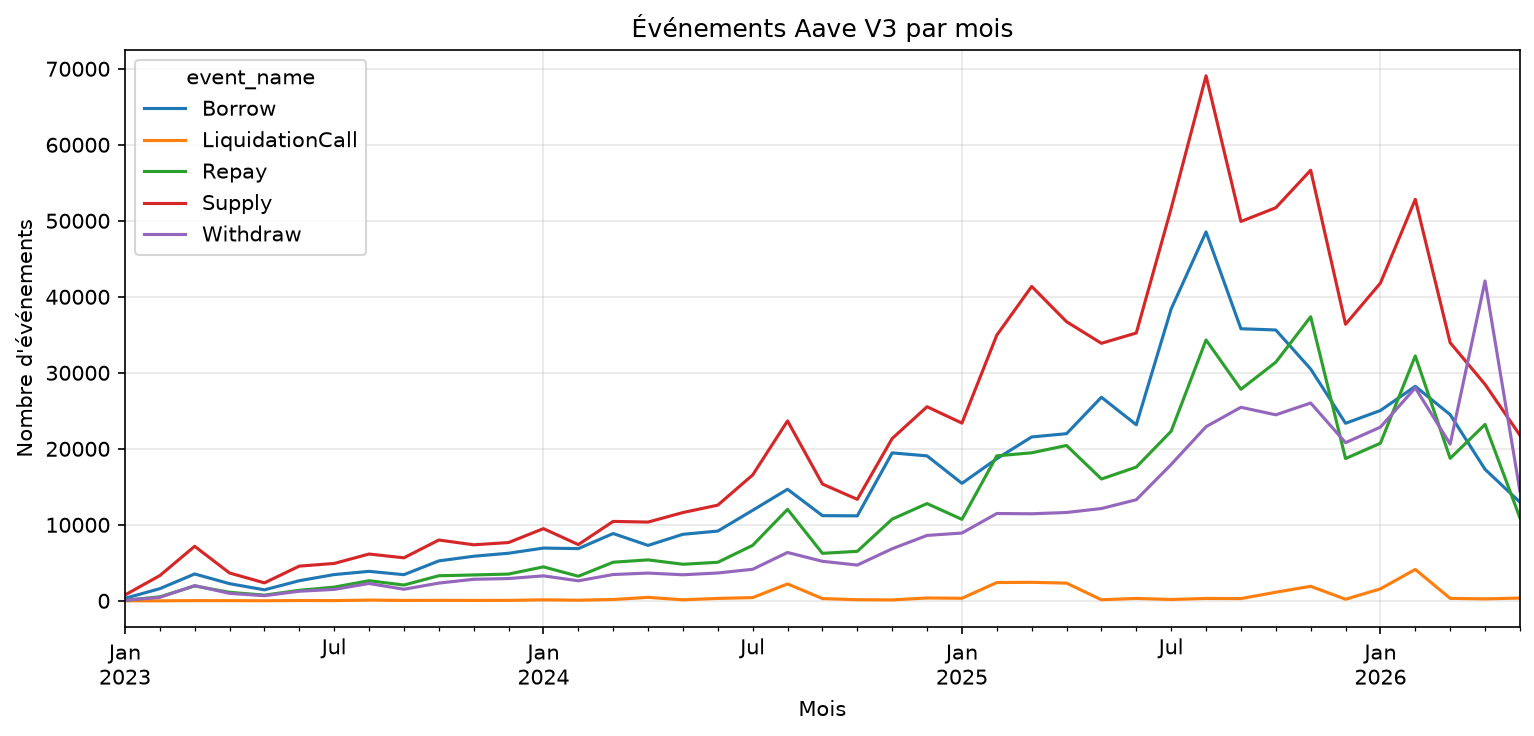

*Nombre d'événements Aave V3 par mois, pour les wallets conservés*

L'activité des wallets conservés sur Aave V3 croît fortement depuis le lancement du protocole en janvier
2023. Elle reste modeste en 2023, augmente nettement à partir de l'été 2024, et atteint un pic en août
2025, avec près de 70 000 dépôts et près de 50 000 emprunts dans le mois. Elle recule ensuite en 2026.

Les dépôts (Supply) sont toujours les plus nombreux, devant les emprunts (Borrow), les remboursements
(Repay) et les retraits (Withdraw). Les liquidations restent rares, mais surviennent par pics : à l'été
2024, au printemps 2025 et surtout en février 2026, avec environ 4 000 liquidations dans le mois. Ce
fonctionnement par vagues rejoint l'observation de Chiu (2026) sur Aave V3. On note aussi un pic de
retraits en avril 2026, avec plus de 40 000 retraits, alors que les autres actions reculent.

### 7.2 Long, court, looping : comment lire l'exposition
Être long sur un actif, c'est gagner quand son prix monte : c'est le cas de quelqu'un qui achète de l'ETH
et le garde. Être court, c'est gagner quand il baisse : on emprunte l'actif, on le vend tout de suite, et
on devra le rendre plus tard ; s'il a baissé entre-temps, on le rachète moins cher pour rembourser et on
garde la différence.

Aave permet de prendre ces positions avec effet de levier. Un utilisateur peut déposer de l'ETH en
garantie, emprunter des dollars, puis racheter de l'ETH avec ces dollars. Il détient alors plus d'ETH
qu'au départ, financé par une dette en dollars : si l'ETH monte, il gagne davantage que s'il l'avait
simplement gardé, mais s'il baisse, il perd davantage et risque la liquidation.

Faute de prix, nous ne mesurons pas l'ampleur du levier. Nous regardons, pour chaque utilisateur et chaque
famille, ce qu'il détient (son avoir) et ce qu'il doit à Aave (sa dette), et nous le rangeons dans l'un des
profils suivants. L'ordre compte : un utilisateur prend le premier profil dont il remplit la condition.

| Profil | Il détient | Il doit | Lecture |
|---|---|---|---|
| épargnant | au moins une famille | rien | il place son argent sans s'endetter |
| long ETH avec levier | de l'ETH | des dollars | il gagne si l'ETH monte |
| long BTC avec levier | du bitcoin | des dollars | il gagne si le bitcoin monte |
| court ETH | des dollars | de l'ETH | il gagne si l'ETH baisse |
| looping | une famille | la même famille | il dépose et emprunte le même actif, souvent pour amplifier un rendement |
| autre emprunteur | | | toute autre combinaison avec une dette |

Pourquoi un utilisateur qui doit des dollars et détient de l'ETH est-il long sur l'ETH ? Sa dette est
fixe en dollars, alors que ce qu'il détient prend de la valeur quand l'ETH monte : sa position
s'apprécie avec l'ETH.

### 7.3 L'exposition de l'ensemble des utilisateurs
On additionne les soldes de tous les utilisateurs, mois par mois, pour chaque famille. La courbe « net »
est la différence entre ce qui est détenu et ce qui est dû à Aave : au-dessus de zéro, les utilisateurs
sont globalement exposés positivement à la famille.

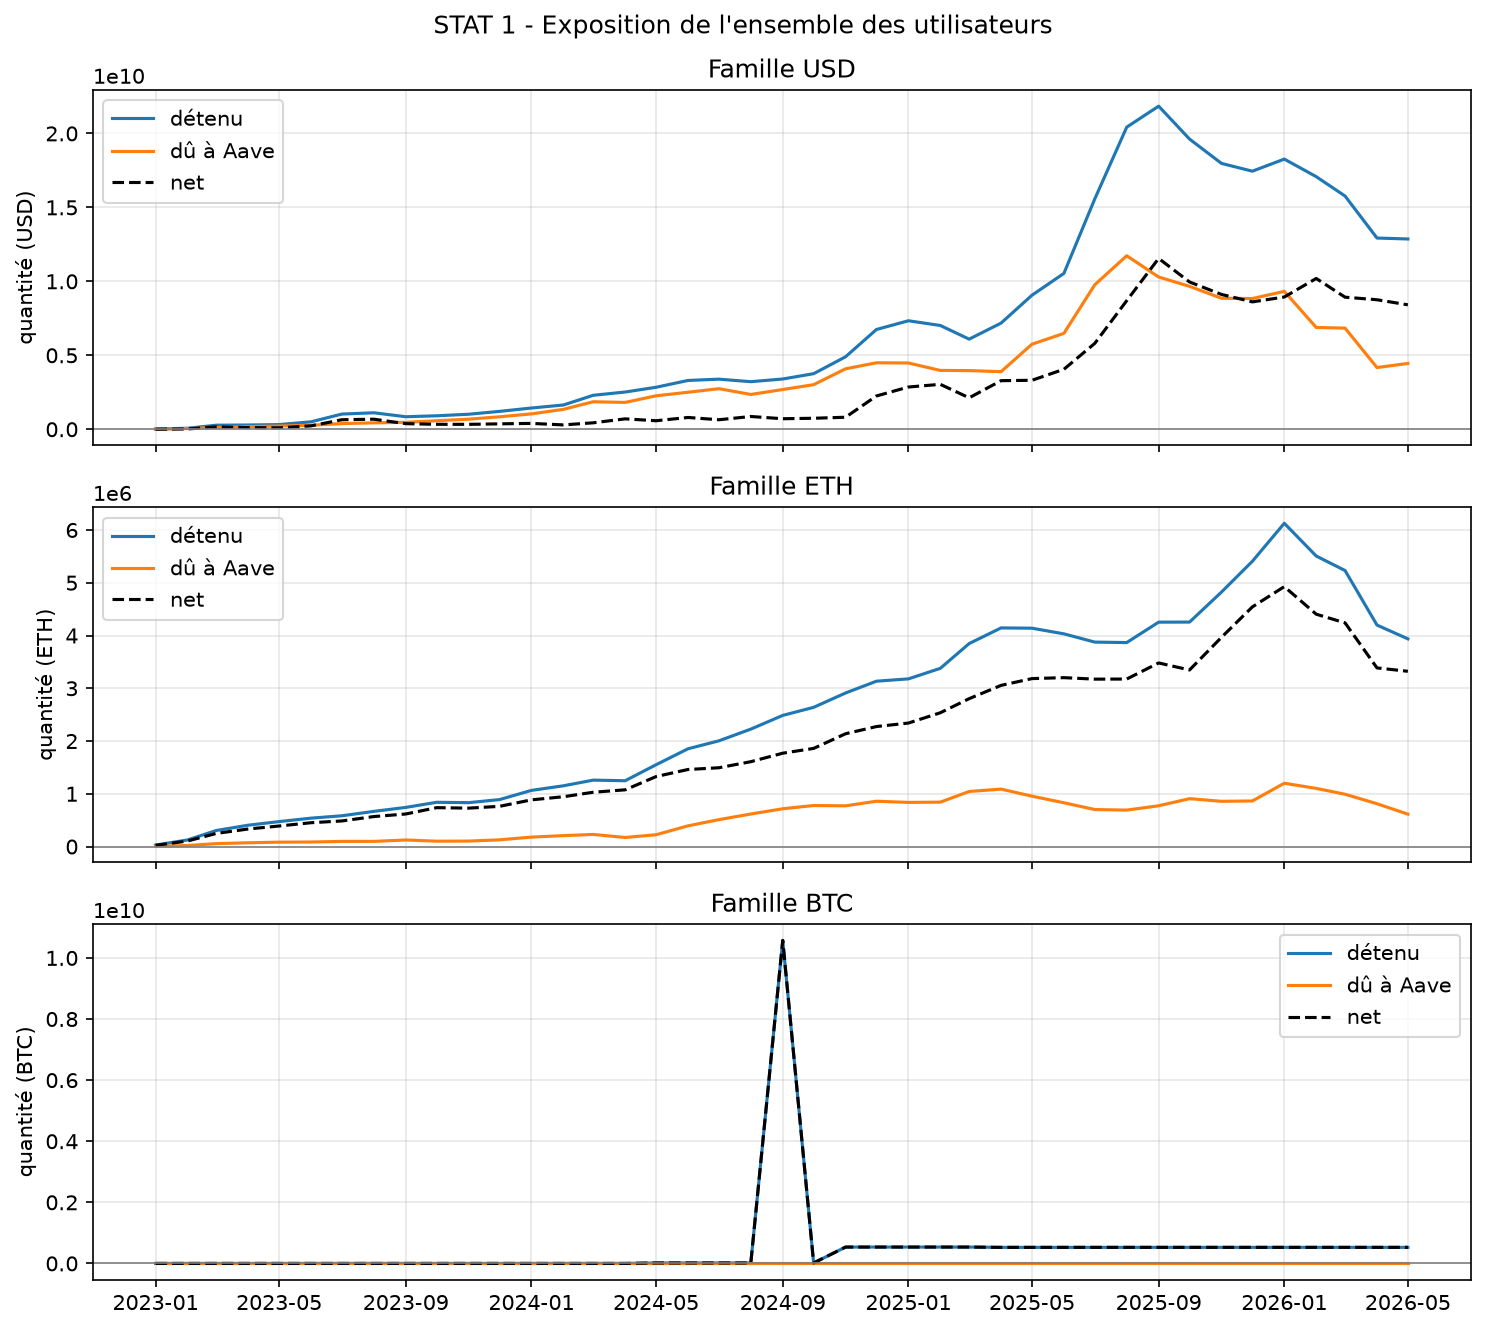

*Quantités détenues, dues à Aave et nettes, pour l'ensemble des utilisateurs*

Pour l'ETH, la quantité détenue grâce à Aave augmente régulièrement de 2023 à janvier 2026, où elle
dépasse 6 millions d'ETH, puis redescend à environ 4 millions en mai 2026. La dette en ETH reste beaucoup
plus faible, autour de 1 million d'ETH au plus. L'exposition nette à l'ETH est donc largement positive
sur toute la période, autour de 3,3 millions d'ETH en mai 2026 : dans l'ensemble, l'argent passé par
Aave se retrouve détenu en ETH bien plus qu'il n'est emprunté en ETH.

Pour les dollars, la quantité détenue et la dette progressent ensemble jusqu'à un pic à l'été 2025,
autour de 22 milliards de dollars détenus et 12 milliards dus, puis reculent. L'exposition nette en
dollars reste positive, alors qu'on aurait pu attendre une dette nette en dollars si tous les
utilisateurs empruntaient des dollars pour acheter de l'ETH. Cela s'explique par le poids des dépôts : les
dollars déposés sur Aave, conservés sous forme d'aTokens, comptent dans ce qui est détenu. La baisse de la
dette en dollars à partir de 2026 indique que les utilisateurs remboursent leurs emprunts.

La famille BTC présente une anomalie : un pic en septembre 2024 puis un niveau de l'ordre de plusieurs
centaines de millions de bitcoins, alors qu'il n'en existe qu'environ 21 millions. Ces quantités
proviennent très probablement d'un token mal décrit (par exemple un nombre de décimales erroné) classé
dans la famille BTC. Les résultats de cette famille ne doivent donc pas être interprétés.

### 7.4 Les profils des utilisateurs

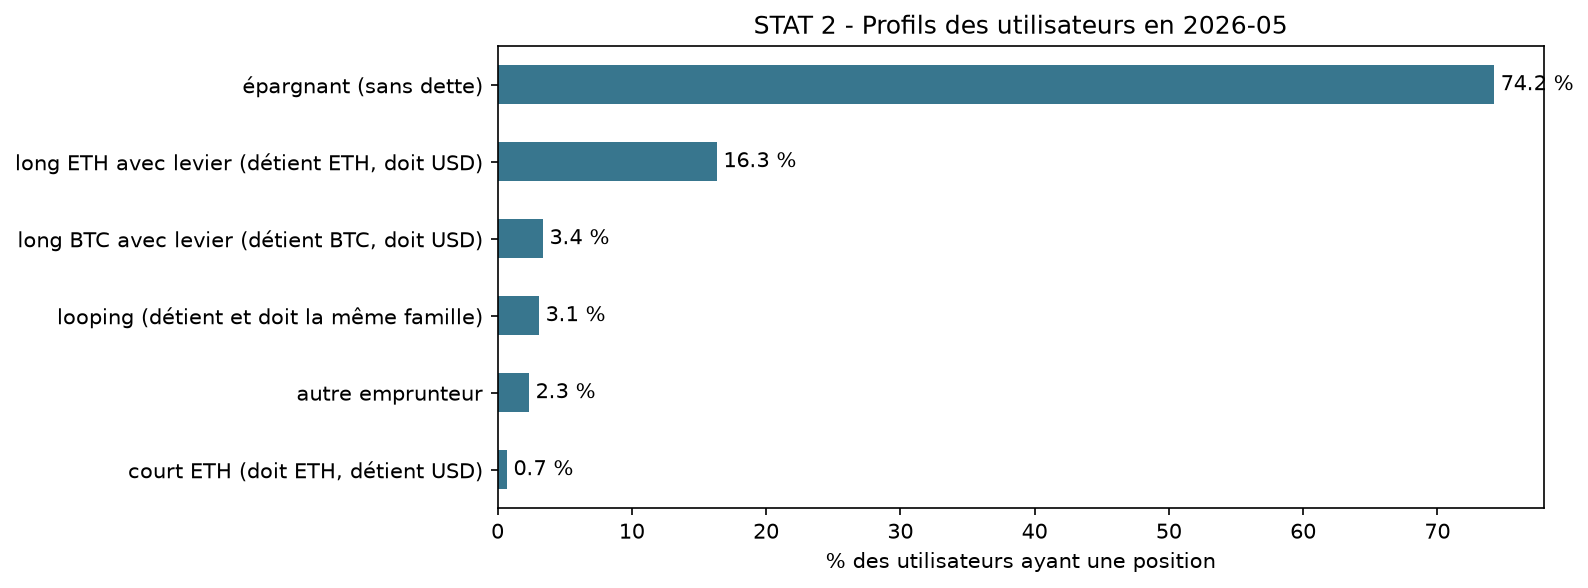

*Profil des utilisateurs ayant une position en mai 2026*

En mai 2026, environ trois utilisateurs sur quatre ayant encore une position sont des épargnants (74 %) :
ils détiennent de l'argent issu d'Aave sans rien lui devoir. Le quart restant a une dette, et parmi ces
emprunteurs, le profil long ETH avec levier domine très largement : il concerne 16,3 % des utilisateurs,
soit près des deux tiers des emprunteurs. Viennent ensuite les profils long BTC avec levier (3,4 %) et
looping (3,1 %). Les positions courtes sur l'ETH sont très rares (0,7 %).

Quand les utilisateurs empruntent sur Aave, c'est donc d'abord pour accroître leur exposition à l'ETH,
ce qui est cohérent avec la conclusion de Cornelli et al. (2025), selon laquelle l'emprunt sur Aave est
surtout motivé par la spéculation. La part du looping paraît plus faible que ne le suggère Chiu (2026),
mais notre définition est plus étroite : nous ne la repérons que lorsque l'utilisateur détient et doit
la même famille avec de l'argent tracé, et nous écartons les jetons de staking.

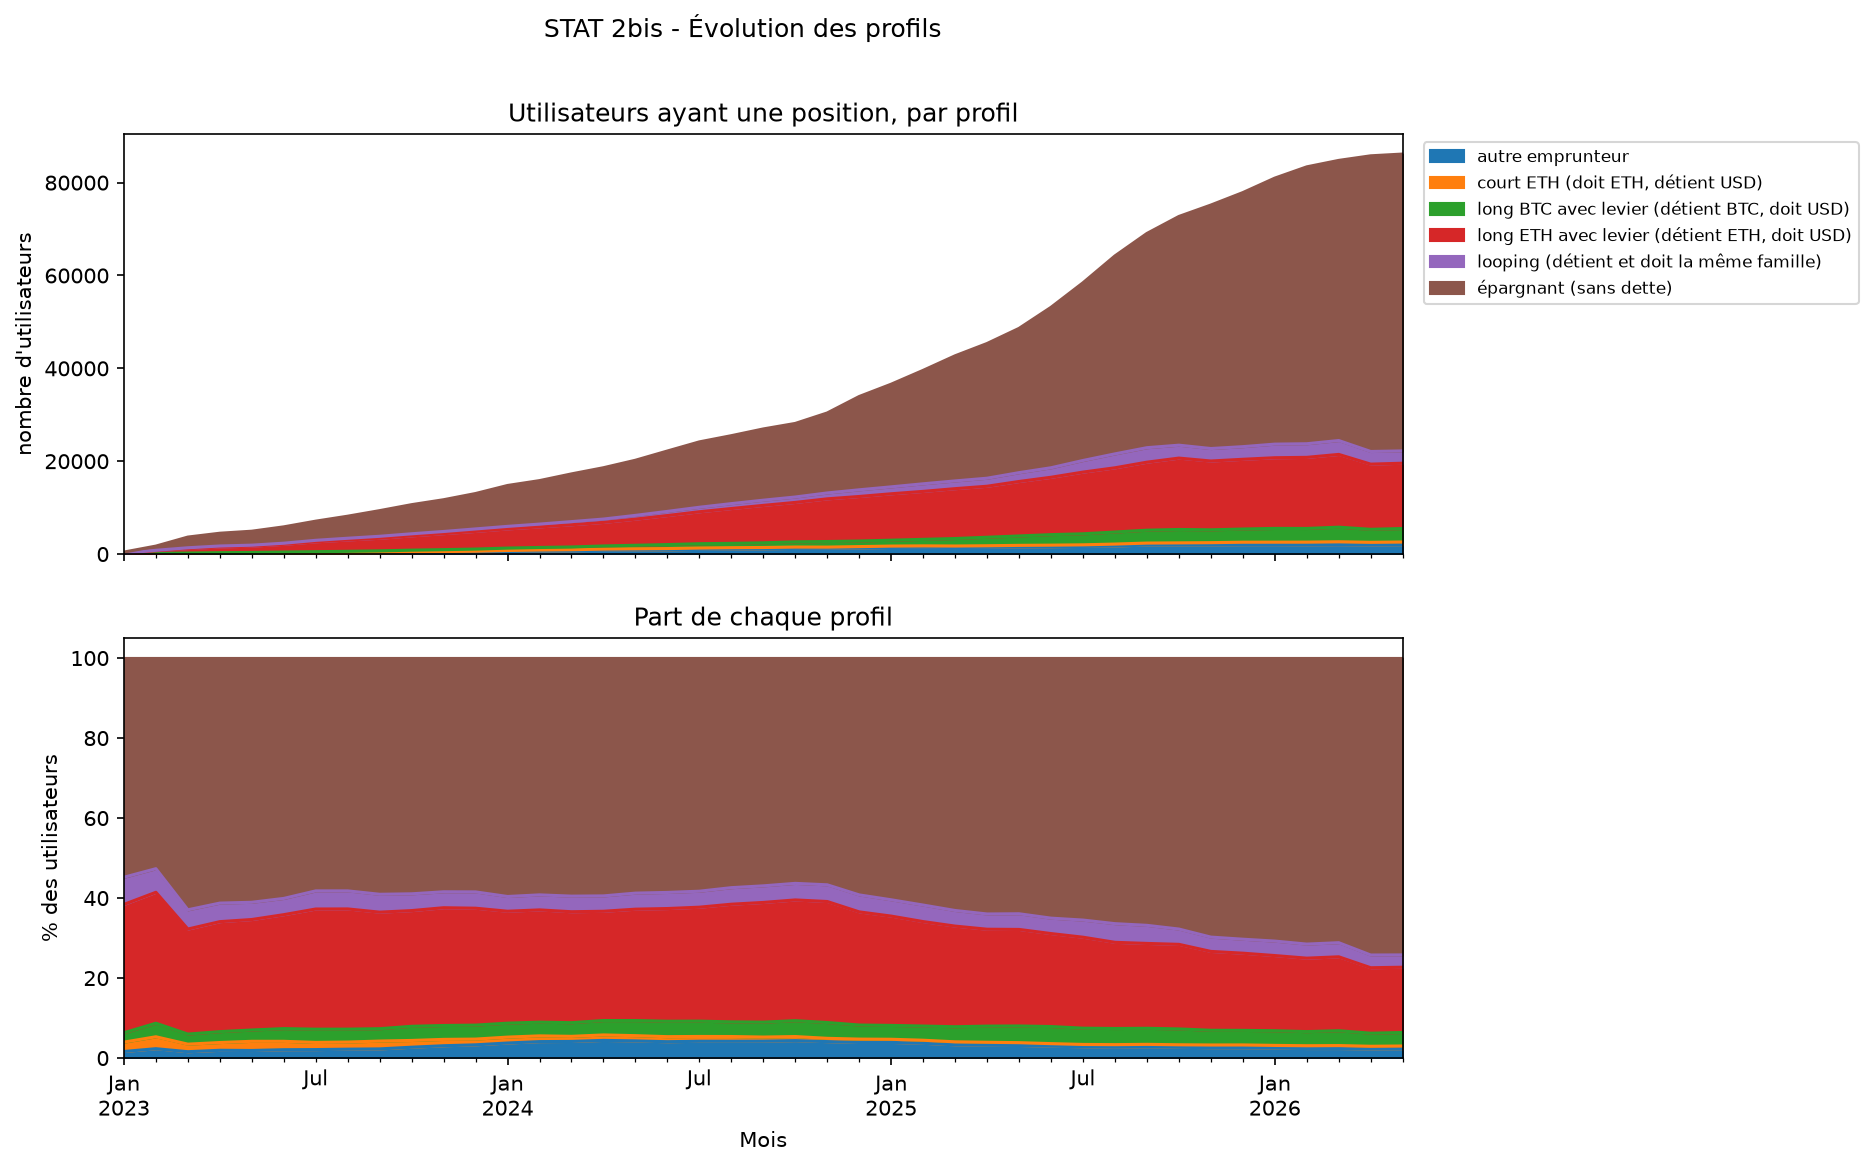

*Évolution du nombre et de la part de chaque profil, mois par mois*

Le nombre d'utilisateurs ayant une position augmente continûment, d'environ 15 000 début 2024 à plus de
85 000 en mai 2026, avec une accélération à partir de 2025. Cette hausse vient surtout des épargnants.

La part des emprunteurs, elle, diminue. Elle tourne autour de 40 % des utilisateurs en 2023 et 2024, puis
recule à partir de fin 2024 pour atteindre environ 26 % en mai 2026. Le profil long ETH avec levier reste
le principal profil d'emprunteur sur toute la période : il représente environ 30 % des utilisateurs en
2023 et 2024, puis environ 16 % en mai 2026. En nombre, il continue pourtant de progresser jusqu'à début
2026, avant de reculer légèrement. Les positions courtes, déjà rares, deviennent marginales, tandis que le
looping reste stable, autour de 3 à 4 % des utilisateurs.

### 7.5 La variation de l'exposition nette
Pour repérer les mois où l'exposition change brutalement, on calcule la variation en pourcentage de
l'exposition nette d'un mois sur l'autre. Les variations calculées sur une base trop petite (moins de 1 %
du maximum de la famille) ou lorsque l'exposition change de signe ne sont pas affichées, car elles
n'auraient pas de sens.

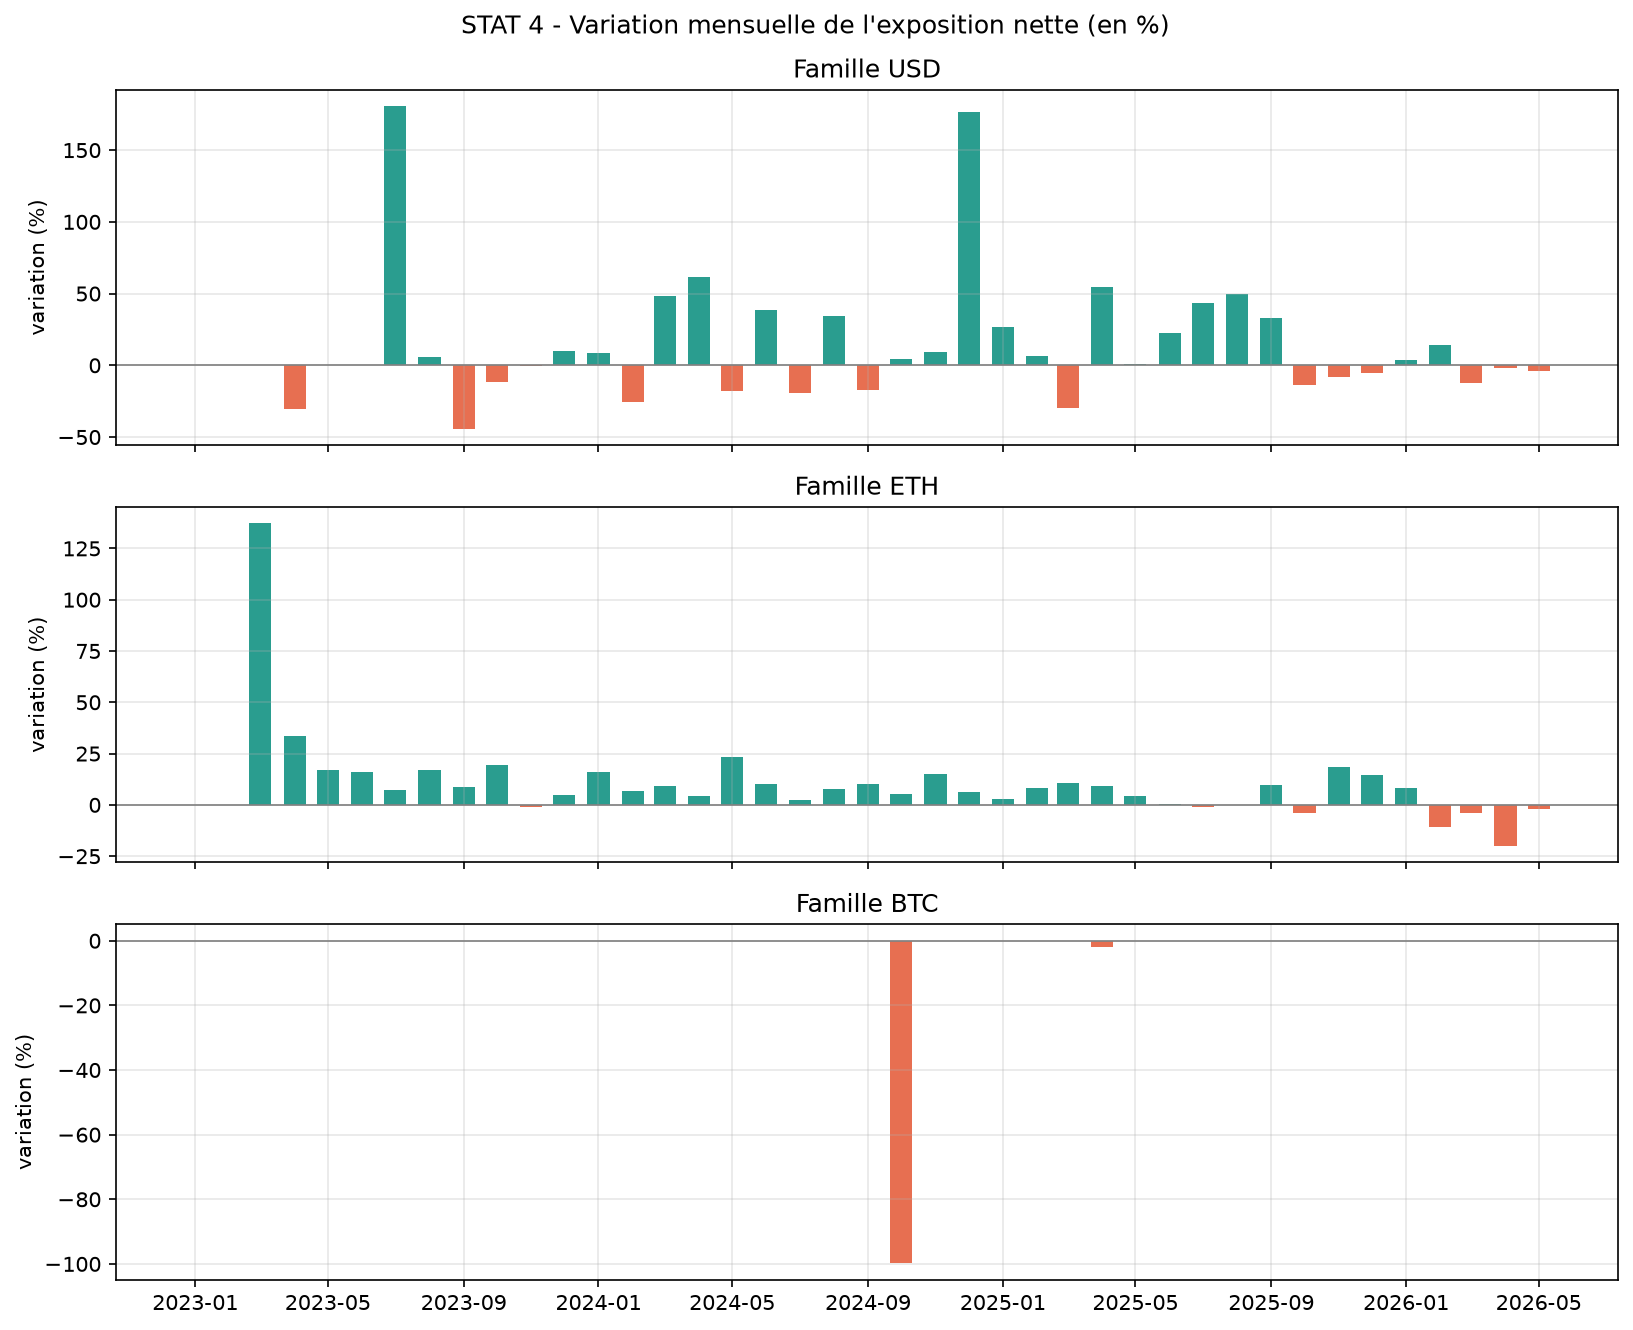

*Variation mensuelle de l'exposition nette, en pourcentage*

Pour l'ETH, l'exposition nette augmente presque chaque mois de 2023 à mi-2025, d'abord très fortement au
lancement du protocole (+137 % en mars 2023), puis de 5 à 20 % par mois. La tendance s'inverse en 2026,
avec des baisses en février (environ −11 %) et surtout en avril (environ −20 %). Ces deux mois
correspondent aux pics observés en 7.1 : la vague de liquidations de février 2026 et le pic de retraits
d'avril 2026. Les utilisateurs réduisent alors leur exposition à l'ETH, soit parce que leurs positions
sont liquidées, soit parce qu'ils retirent leurs fonds.

Pour les dollars, les variations sont plus irrégulières, avec deux hausses ponctuelles très fortes, en
juillet 2023 et en décembre 2024 (près de +180 %), et une série de légères baisses à partir de l'automne
2025, qui accompagne le recul de l'activité.

Pour le bitcoin, la baisse de −100 % en octobre 2024 correspond à la disparition du pic anormal de
septembre 2024 relevé en 7.3, et ne doit pas être interprétée.